# Cálculo Numérico — Atividade Prática III

**Raízes por Bisseção, Newton e Secante**  
Disciplina: Cálculo Numérico · Prof.ª Raquel J. Lobosco  
Aluno: Pedro Henrique Moreira Oliveira

Este relatório computacional implementa manualmente os três métodos, executa os 12 casos do enunciado, valida os resíduos e gera os arquivos usados no dashboard do Mathcha.


[**Abrir notebook no Google Colab ↗**](https://colab.research.google.com/drive/1FAhXt0_V3iNqLZA3MsjNvorEmtYeY4mf)

## Síntese executiva

- Os **12 testes principais convergiram** com os valores iniciais solicitados.
- Newton precisou de **3 a 4 iterações**, a Secante de **5 a 7** e a Bisseção de **20 a 22**.
- Todos os resíduos finais ficaram abaixo de `1e-6`.
- Em `f4`, Newton converge com `x0=-2`, mas o experimento adicional `x0=0` revela o ciclo `0 → 1 → 0 → …`.

## 1. Introdução

Uma raiz de uma função é um valor $r$ que satisfaz $f(r)=0$. Quando não existe uma fórmula direta conveniente, métodos iterativos constroem aproximações sucessivas. Nesta atividade, cada algoritmo foi escrito manualmente e retorna a raiz aproximada, o histórico, o resíduo, o número de iterações e uma mensagem de parada.

In [1]:
from pathlib import Path
import math
import os
import tempfile

import numpy as np
import pandas as pd
_MPL_CACHE = Path(tempfile.gettempdir()) / "atividade_cn_matplotlib"
_MPL_CACHE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(_MPL_CACHE))
os.environ.setdefault("XDG_CACHE_HOME", str(_MPL_CACHE))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image as IPythonImage, display
from PIL import Image as PILImage

TOL = 1e-6
MAX_ITER = 100
ZERO_TOL = 1e-12

PROJECT_DIR = Path.cwd()
GIF_DIR = PROJECT_DIR / "gifs"
GIF_DIR.mkdir(parents=True, exist_ok=True)
COLAB_URL = "https://colab.research.google.com/drive/1FAhXt0_V3iNqLZA3MsjNvorEmtYeY4mf"

## 2. Funções investigadas

\[
f_1(x)=x^2-2,\quad
f_2(x)=x^3-x-2,\quad
f_3(x)=e^{-x}-x,\quad
f_4(x)=x^3-2x+2.
\]

Para Newton, usam-se as derivadas analíticas $f'_1(x)=2x$, $f'_2(x)=3x^2-1$, $f'_3(x)=-e^{-x}-1$ e $f'_4(x)=3x^2-2$.

In [2]:
def f1(x):
    return x**2 - 2


def df1(x):
    return 2*x


def f2(x):
    return x**3 - x - 2


def df2(x):
    return 3*x**2 - 1


def f3(x):
    return np.exp(-x) - x


def df3(x):
    return -np.exp(-x) - 1


def f4(x):
    return x**3 - 2*x + 2


def df4(x):
    return 3*x**2 - 2

## 3. Critérios de convergência

Os parâmetros são `tol=1e-6`, `max_iter=100` e `ZERO_TOL=1e-12`. O **passo** $|x_{k+1}-x_k|$ mede quanto a aproximação mudou; o **resíduo** $|f(x_{k+1})|$ mede quão perto a equação está de zero.

A parada exige simultaneamente:

\[
|x_{k+1}-x_k|<10^{-6}
\quad\textbf{e}\quad
|f(x_{k+1})|<10^{-6}.
\]

O teste duplo evita aceitar um passo pequeno longe de uma raiz. O limiar `ZERO_TOL=1e-12` impede divisões numericamente instáveis por derivadas ou denominadores praticamente nulos.

## 4. Método da Bisseção

Se $f(a)f(b)<0$, a continuidade garante pelo menos uma raiz em $[a,b]$. Calcula-se $c=(a+b)/2$ e conserva-se a metade que mantém a mudança de sinal. O intervalo é reduzido de forma previsível, embora a convergência seja linear.

## 5. Método de Newton

Newton usa a reta tangente em $(x_k,f(x_k))$:

\[
x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}.
\]

A interseção dessa tangente com o eixo x fornece a nova aproximação. A convergência costuma ser rápida perto da raiz, mas depende de $x_0$ e falha quando $f'(x_k)$ é muito pequena.

## 6. Método da Secante

A Secante substitui a derivada analítica pela inclinação entre dois pontos:

\[
x_{k+1}=x_k-f(x_k)\frac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})}.
\]

Ela dispensa $f'(x)$, mas depende de dois valores iniciais e não pode continuar quando $f(x_k)-f(x_{k-1})$ fica numericamente nulo. As três implementações aparecem juntas na célula seguinte para facilitar reutilização.

In [3]:
CHAVES_RESULTADO = {
    "raiz",
    "iteracoes",
    "historico",
    "residuo",
    "convergiu",
    "mensagem",
    "passos",
}


def _resultado(raiz, iteracoes, historico, residuo, convergiu, mensagem, passos):
    return {
        "raiz": float(raiz),
        "iteracoes": int(iteracoes),
        "historico": [float(x) for x in historico],
        "residuo": float(residuo),
        "convergiu": bool(convergiu),
        "mensagem": str(mensagem),
        "passos": passos,
    }


def _falha_sem_aproximacao(mensagem):
    return _resultado(np.nan, 0, [], np.nan, False, mensagem, [])


def _escalar_finito(valor):
    try:
        escalar = float(valor)
    except (TypeError, ValueError, OverflowError):
        return None
    return escalar if np.isfinite(escalar) else None


def _avaliar(funcao, x):
    try:
        valor = _escalar_finito(funcao(x))
    except (ArithmeticError, TypeError, ValueError, OverflowError):
        return None
    return valor


def bissecao(f, a, b, tol=TOL, max_iter=MAX_ITER):
    """Aproxima uma raiz por redução sucessiva de um intervalo com mudança de sinal."""
    a = _escalar_finito(a)
    b = _escalar_finito(b)
    if a is None or b is None:
        return _falha_sem_aproximacao("Os extremos devem ser números finitos.")

    fa = _avaliar(f, a)
    fb = _avaliar(f, b)
    if fa is None or fb is None:
        return _falha_sem_aproximacao("A função deve produzir valores finitos nos extremos.")

    if abs(fa) < tol:
        return _resultado(a, 0, [a], abs(fa), True, "Raiz encontrada no extremo inicial a.", [])
    if abs(fb) < tol:
        return _resultado(b, 0, [b], abs(fb), True, "Raiz encontrada no extremo inicial b.", [])
    if fa * fb > 0:
        return _resultado(
            np.nan,
            0,
            [],
            np.nan,
            False,
            "O intervalo não apresenta mudança de sinal; o Teorema do Valor Intermediário não garante uma raiz.",
            [],
        )

    historico = []
    passos = []
    anterior = None
    ultimo_residuo = np.nan

    for iteracao in range(1, int(max_iter) + 1):
        c = (a + b) / 2.0
        fc = _avaliar(f, c)
        if fc is None:
            raiz = historico[-1] if historico else np.nan
            return _resultado(
                raiz,
                iteracao - 1,
                historico,
                ultimo_residuo,
                False,
                "A função produziu valor não finito durante a bisseção.",
                passos,
            )

        residuo = abs(fc)
        historico.append(c)

        if fa * fc <= 0:
            a_novo, b_novo = a, c
            fa_novo, fb_novo = fa, fc
        else:
            a_novo, b_novo = c, b
            fa_novo, fb_novo = fc, fb

        passos.append(
            {
                "iteracao": iteracao,
                "a": a,
                "b": b,
                "fa": fa,
                "fb": fb,
                "c": c,
                "fc": fc,
                "a_novo": a_novo,
                "b_novo": b_novo,
                "residuo": residuo,
            }
        )

        if anterior is None and residuo < tol:
            return _resultado(c, iteracao, historico, residuo, True, "Convergiu: ponto médio já satisfaz a tolerância do resíduo.", passos)
        if anterior is not None and abs(c - anterior) < tol and residuo < tol:
            return _resultado(c, iteracao, historico, residuo, True, "Convergiu pelos critérios de passo e resíduo.", passos)

        a, b, fa, fb = a_novo, b_novo, fa_novo, fb_novo
        anterior = c
        ultimo_residuo = residuo

    raiz = historico[-1] if historico else np.nan
    return _resultado(
        raiz,
        int(max_iter),
        historico,
        abs(_avaliar(f, raiz)) if historico else np.nan,
        False,
        f"Número máximo de {max_iter} iterações atingido sem convergência.",
        passos,
    )


def newton(f, df, x0, tol=TOL, max_iter=MAX_ITER):
    """Aproxima uma raiz usando interseções de retas tangentes com o eixo x."""
    x = _escalar_finito(x0)
    if x is None:
        return _falha_sem_aproximacao("O valor inicial deve ser um número finito.")

    fx = _avaliar(f, x)
    if fx is None:
        return _falha_sem_aproximacao("A função deve produzir valor finito no ponto inicial.")
    if abs(fx) < tol:
        return _resultado(x, 0, [x], abs(fx), True, "Raiz encontrada no valor inicial.", [])

    historico = [x]
    passos = []

    for iteracao in range(1, int(max_iter) + 1):
        dfx = _avaliar(df, x)
        if dfx is None:
            return _resultado(x, iteracao - 1, historico, abs(fx), False, "A derivada produziu valor não finito.", passos)
        if abs(dfx) < ZERO_TOL:
            return _resultado(x, iteracao - 1, historico, abs(fx), False, "Derivada nula ou muito próxima de zero; Newton não pode continuar.", passos)

        x_novo = _escalar_finito(x - fx / dfx)
        if x_novo is None:
            return _resultado(x, iteracao - 1, historico, abs(fx), False, "A atualização de Newton produziu valor não finito.", passos)
        f_novo = _avaliar(f, x_novo)
        if f_novo is None:
            return _resultado(x, iteracao - 1, historico, abs(fx), False, "A função produziu valor não finito após a atualização de Newton.", passos)

        passo = abs(x_novo - x)
        residuo = abs(f_novo)
        passos.append(
            {
                "iteracao": iteracao,
                "x": x,
                "fx": fx,
                "dfx": dfx,
                "x_novo": x_novo,
                "f_novo": f_novo,
                "passo": passo,
                "residuo": residuo,
            }
        )
        historico.append(x_novo)

        if passo < tol and residuo < tol:
            return _resultado(x_novo, iteracao, historico, residuo, True, "Convergiu pelos critérios de passo e resíduo.", passos)

        x, fx = x_novo, f_novo

    return _resultado(
        x,
        int(max_iter),
        historico,
        abs(fx),
        False,
        f"Número máximo de {max_iter} iterações atingido sem convergência.",
        passos,
    )


def secante(f, x0, x1, tol=TOL, max_iter=MAX_ITER):
    """Aproxima uma raiz por retas secantes construídas com dois pontos anteriores."""
    x_anterior = _escalar_finito(x0)
    x_atual = _escalar_finito(x1)
    if x_anterior is None or x_atual is None:
        return _falha_sem_aproximacao("Os valores iniciais devem ser números finitos.")

    f_anterior = _avaliar(f, x_anterior)
    f_atual = _avaliar(f, x_atual)
    if f_anterior is None or f_atual is None:
        return _falha_sem_aproximacao("A função deve produzir valores finitos nos pontos iniciais.")

    historico = [x_anterior, x_atual]
    if abs(f_anterior) < tol:
        return _resultado(x_anterior, 0, historico, abs(f_anterior), True, "Raiz encontrada no primeiro valor inicial.", [])
    if abs(f_atual) < tol:
        return _resultado(x_atual, 0, historico, abs(f_atual), True, "Raiz encontrada no segundo valor inicial.", [])

    passos = []
    for iteracao in range(1, int(max_iter) + 1):
        denominador = f_atual - f_anterior
        if abs(denominador) < ZERO_TOL:
            return _resultado(
                x_atual,
                iteracao - 1,
                historico,
                abs(f_atual),
                False,
                "Denominador nulo ou muito próximo de zero; a Secante não pode continuar.",
                passos,
            )

        x_novo = _escalar_finito(x_atual - f_atual * (x_atual - x_anterior) / denominador)
        if x_novo is None:
            return _resultado(x_atual, iteracao - 1, historico, abs(f_atual), False, "A atualização da Secante produziu valor não finito.", passos)
        f_novo = _avaliar(f, x_novo)
        if f_novo is None:
            return _resultado(x_atual, iteracao - 1, historico, abs(f_atual), False, "A função produziu valor não finito após a atualização da Secante.", passos)

        passo = abs(x_novo - x_atual)
        residuo = abs(f_novo)
        passos.append(
            {
                "iteracao": iteracao,
                "x_anterior": x_anterior,
                "f_anterior": f_anterior,
                "x_atual": x_atual,
                "f_atual": f_atual,
                "x_novo": x_novo,
                "f_novo": f_novo,
                "passo": passo,
                "residuo": residuo,
            }
        )
        historico.append(x_novo)

        if passo < tol and residuo < tol:
            return _resultado(x_novo, iteracao, historico, residuo, True, "Convergiu pelos critérios de passo e resíduo.", passos)

        x_anterior, f_anterior = x_atual, f_atual
        x_atual, f_atual = x_novo, f_novo

    return _resultado(
        x_atual,
        int(max_iter),
        historico,
        abs(f_atual),
        False,
        f"Número máximo de {max_iter} iterações atingido sem convergência.",
        passos,
    )

## 7. Aplicação dos métodos

As configurações abaixo centralizam função, derivada e valores iniciais. Alterar `TOL`, `MAX_ITER` ou uma entrada da lista refaz toda a matriz sem reescrever os algoritmos.

In [4]:
CONFIGURACOES = [
    {
        "nome": "f1",
        "rotulo": "f1(x) = x² - 2",
        "funcao": f1,
        "derivada": df1,
        "casos": [
            {"metodo": "bissecao", "iniciais": (1.0, 2.0)},
            {"metodo": "newton", "iniciais": (1.5,)},
            {"metodo": "secante", "iniciais": (1.0, 2.0)},
        ],
    },
    {
        "nome": "f2",
        "rotulo": "f2(x) = x³ - x - 2",
        "funcao": f2,
        "derivada": df2,
        "casos": [
            {"metodo": "bissecao", "iniciais": (1.0, 2.0)},
            {"metodo": "newton", "iniciais": (1.5,)},
            {"metodo": "secante", "iniciais": (1.0, 2.0)},
        ],
    },
    {
        "nome": "f3",
        "rotulo": "f3(x) = exp(-x) - x",
        "funcao": f3,
        "derivada": df3,
        "casos": [
            {"metodo": "bissecao", "iniciais": (0.0, 1.0)},
            {"metodo": "newton", "iniciais": (0.5,)},
            {"metodo": "secante", "iniciais": (0.0, 1.0)},
        ],
    },
    {
        "nome": "f4",
        "rotulo": "f4(x) = x³ - 2x + 2",
        "funcao": f4,
        "derivada": df4,
        "casos": [
            {"metodo": "bissecao", "iniciais": (-2.0, -1.0)},
            {"metodo": "newton", "iniciais": (-2.0,)},
            {"metodo": "secante", "iniciais": (-2.0, -1.0)},
        ],
    },
]

NOMES_METODOS = {
    "bissecao": "Bisseção",
    "newton": "Newton",
    "secante": "Secante",
}


def _texto_iniciais(metodo, iniciais):
    if metodo == "bissecao":
        return f"[{iniciais[0]:g}, {iniciais[1]:g}]"
    if metodo == "newton":
        return f"x0 = {iniciais[0]:g}"
    return f"({iniciais[0]:g}, {iniciais[1]:g})"


def executar_experimentos(tol=TOL, max_iter=MAX_ITER):
    linhas = []
    detalhes = {}

    for configuracao in CONFIGURACOES:
        nome = configuracao["nome"]
        f = configuracao["funcao"]
        df = configuracao["derivada"]

        for caso in configuracao["casos"]:
            metodo = caso["metodo"]
            iniciais = caso["iniciais"]

            if metodo == "bissecao":
                resultado = bissecao(f, *iniciais, tol=tol, max_iter=max_iter)
            elif metodo == "newton":
                resultado = newton(f, df, *iniciais, tol=tol, max_iter=max_iter)
            else:
                resultado = secante(f, *iniciais, tol=tol, max_iter=max_iter)

            nome_metodo = NOMES_METODOS[metodo]
            detalhes[(nome, nome_metodo)] = resultado
            linhas.append(
                {
                    "Função": configuracao["rotulo"],
                    "Método": nome_metodo,
                    "Valores iniciais": _texto_iniciais(metodo, iniciais),
                    "Raiz aproximada": resultado["raiz"],
                    "|f(x)| final": resultado["residuo"],
                    "Iterações": resultado["iteracoes"],
                    "Resultado": "Convergiu" if resultado["convergiu"] else resultado["mensagem"],
                }
            )

    return pd.DataFrame(linhas), detalhes

## 8. Tabela comparativa

A tabela é construída automaticamente e exportada para `resultados.csv`. A exibição usa 12 casas decimais nas raízes e notação científica nos resíduos; o CSV mantém os valores numéricos completos.

In [5]:
df_resultados, resultados_detalhados = executar_experimentos()
RESULTADOS_CSV = PROJECT_DIR / "resultados.csv"
df_resultados.to_csv(RESULTADOS_CSV, index=False)

formatos_tabela = {
    "Raiz aproximada": lambda valor: f"{valor:.12f}" if np.isfinite(valor) else "—",
    "|f(x)| final": lambda valor: f"{valor:.3e}" if np.isfinite(valor) else "—",
}
df_resultados_formatado = df_resultados.copy()
for coluna, formatador in formatos_tabela.items():
    df_resultados_formatado[coluna] = df_resultados_formatado[coluna].map(formatador)
df_resultados_formatado

,Função,Método,Valores iniciais,Raiz aproximada,|f(x)| final,Iterações,Resultado
0,f1(x) = x² - 2,Bisseção,"[1, 2]",1.414213657379,2.687e-07,21,Convergiu
1,f1(x) = x² - 2,Newton,x0 = 1.5,1.414213562373,4.441e-16,4,Convergiu
2,f1(x) = x² - 2,Secante,"(1, 2)",1.414213562373,8.882e-16,6,Convergiu
3,f2(x) = x³ - x - 2,Bisseção,"[1, 2]",1.521379709244,1.450e-08,22,Convergiu
4,f2(x) = x³ - x - 2,Newton,x0 = 1.5,1.521379706805,4.530e-14,3,Convergiu
5,f2(x) = x³ - x - 2,Secante,"(1, 2)",1.521379706805,1.843e-14,7,Convergiu
6,f3(x) = exp(-x) - x,Bisseção,"[0, 1]",0.567143440247,2.348e-07,20,Convergiu
7,f3(x) = exp(-x) - x,Newton,x0 = 0.5,0.567143290410,4.441e-15,3,Convergiu
8,f3(x) = exp(-x) - x,Secante,"(0, 1)",0.567143290410,1.242e-13,5,Convergiu
9,f4(x) = x³ - 2x + 2,Bisseção,"[-2, -1]",-1.769292354584,2.551e-09,21,Convergiu


In [6]:
MAPA_FUNCOES = {item["nome"]: item["funcao"] for item in CONFIGURACOES}
validacoes = []
for (nome, metodo), resultado in resultados_detalhados.items():
    residuo_recalculado = abs(MAPA_FUNCOES[nome](resultado["raiz"]))
    valido = bool(resultado["convergiu"] and residuo_recalculado < TOL)
    validacoes.append(
        {
            "Função": nome,
            "Método": metodo,
            "Resíduo recalculado": residuo_recalculado,
            "Válido": valido,
        }
    )

df_validacao = pd.DataFrame(validacoes)
validacao_ok = bool(df_validacao["Válido"].all() and len(df_validacao) == 12)
assert validacao_ok, "Ao menos um resultado convergente não satisfaz o resíduo exigido."
df_validacao

,Função,Método,Resíduo recalculado,Válido
0,f1,Bisseção,2.687177e-07,True
1,f1,Newton,4.440892e-16,True
2,f1,Secante,8.881784e-16,True
3,f2,Bisseção,1.449813e-08,True
4,f2,Newton,4.529710e-14,True
5,f2,Secante,1.842970e-14,True
6,f3,Bisseção,2.348157e-07,True
7,f3,Newton,4.440892e-15,True
8,f3,Secante,1.242340e-13,True
9,f4,Bisseção,2.550763e-09,True


## 9. Animações

Os três GIFs usam `f2(x)=x³-x-2`, o que permite comparar os métodos sob a mesma função. As construções mostram o eixo `y=0`, as aproximações, a geometria usada e o resíduo em cada iteração.

In [7]:
COR_CURVA = "#155E75"
COR_CONSTRUCAO = "#F97316"
COR_NOVO = "#15803D"
COR_INTERVALO = "#7DD3FC"
COR_TEXTO = "#1F2937"


def _preparar_eixos(ax, f, intervalo_plot, titulo):
    x_min, x_max = intervalo_plot
    xs = np.linspace(x_min, x_max, 500)
    ys = np.asarray([f(float(x)) for x in xs], dtype=float)
    amplitude = max(float(np.nanmax(ys) - np.nanmin(ys)), 1.0)
    margem = 0.12 * amplitude
    y_min = min(float(np.nanmin(ys)) - margem, -0.15 * amplitude)
    y_max = max(float(np.nanmax(ys)) + margem, 0.15 * amplitude)

    ax.plot(xs, ys, color=COR_CURVA, linewidth=2.6, label="f(x)")
    ax.axhline(0.0, color="#111827", linewidth=1.4)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_title(titulo, loc="left", fontsize=14, fontweight="bold")
    ax.grid(True, color="#CBD5E1", linewidth=0.7, alpha=0.55)
    return y_min, y_max


def _quadros_com_pausa(passos):
    if not passos:
        raise ValueError("A animação exige ao menos um passo iterativo.")
    ultimo = len(passos) - 1
    return list(range(len(passos))) + [ultimo, ultimo]


def animar_bissecao(f, resultado, intervalo_plot, caminho):
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    passos = resultado["passos"]
    fig, ax = plt.subplots(figsize=(9, 5.5))

    def atualizar(indice):
        ax.clear()
        passo = passos[indice]
        y_min, y_max = _preparar_eixos(
            ax, f, intervalo_plot, "Bisseção — redução do intervalo"
        )
        ax.axvspan(
            passo["a"], passo["b"], color=COR_INTERVALO, alpha=0.17,
            label="intervalo atual",
        )
        ax.axvspan(
            passo["a_novo"], passo["b_novo"], color=COR_NOVO, alpha=0.16,
            label="intervalo preservado",
        )
        ax.axvline(passo["a"], color="#475569", linestyle="--", linewidth=1.1)
        ax.axvline(passo["b"], color="#475569", linestyle="--", linewidth=1.1)
        ax.vlines(
            passo["c"], 0.0, passo["fc"], color=COR_CONSTRUCAO,
            linestyle=":", linewidth=1.7,
        )
        ax.scatter(
            [passo["c"]], [passo["fc"]], color=COR_CONSTRUCAO,
            s=72, zorder=5, label="ponto médio",
        )
        ax.scatter(
            [passo["c"]], [0.0], color=COR_NOVO, marker="D",
            s=54, zorder=5, label="aproximação",
        )
        ax.text(
            0.02,
            0.97,
            (
                f"Iteração {passo['iteracao']}\n"
                f"a = {passo['a']:.8f}   b = {passo['b']:.8f}\n"
                f"c = {passo['c']:.10f}\n"
                f"f(c) = {passo['fc']:.3e}   |f(c)| = {passo['residuo']:.3e}"
            ),
            transform=ax.transAxes,
            va="top",
            color=COR_TEXTO,
            fontsize=10,
            bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#CBD5E1", "alpha": 0.94},
        )
        ax.legend(loc="lower right", frameon=True, fontsize=9)
        ax.set_ylim(y_min, y_max)

    animacao = FuncAnimation(
        fig, atualizar, frames=_quadros_com_pausa(passos), interval=450,
        repeat=False, blit=False,
    )
    animacao.save(caminho, writer=PillowWriter(fps=2), dpi=110)
    plt.close(fig)
    return caminho

In [8]:
def animar_newton(f, df, resultado, intervalo_plot, caminho):
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    passos = resultado["passos"]
    fig, ax = plt.subplots(figsize=(9, 5.5))

    def atualizar(indice):
        ax.clear()
        passo = passos[indice]
        y_min, y_max = _preparar_eixos(
            ax, f, intervalo_plot, "Newton — interseção da reta tangente"
        )
        largura = intervalo_plot[1] - intervalo_plot[0]
        x_tangente = np.linspace(
            max(intervalo_plot[0], passo["x"] - 0.45 * largura),
            min(intervalo_plot[1], passo["x"] + 0.45 * largura),
            120,
        )
        y_tangente = passo["fx"] + passo["dfx"] * (x_tangente - passo["x"])
        ax.plot(
            x_tangente, y_tangente, color=COR_CONSTRUCAO,
            linewidth=2.0, label="reta tangente",
        )
        ax.vlines(
            passo["x"], 0.0, passo["fx"], color="#64748B",
            linestyle=":", linewidth=1.2,
        )
        ax.scatter(
            [passo["x"]], [passo["fx"]], color=COR_CONSTRUCAO,
            s=76, zorder=5, label="(xₖ, f(xₖ))",
        )
        ax.scatter(
            [passo["x_novo"]], [0.0], color=COR_NOVO,
            marker="D", s=62, zorder=5, label="xₖ₊₁",
        )
        ax.plot(
            [passo["x_novo"], passo["x_novo"]],
            [0.0, passo["f_novo"]],
            color=COR_NOVO, linestyle=":", linewidth=1.2,
        )
        ax.scatter(
            [passo["x_novo"]], [passo["f_novo"]],
            facecolor="white", edgecolor=COR_NOVO, linewidth=1.8,
            s=68, zorder=5,
        )
        ax.text(
            0.02,
            0.97,
            (
                f"Iteração {passo['iteracao']}\n"
                f"xₖ = {passo['x']:.10f}\n"
                f"xₖ₊₁ = {passo['x_novo']:.10f}\n"
                f"|f(xₖ₊₁)| = {passo['residuo']:.3e}"
            ),
            transform=ax.transAxes,
            va="top",
            color=COR_TEXTO,
            fontsize=10,
            bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#CBD5E1", "alpha": 0.94},
        )
        ax.legend(loc="lower right", frameon=True, fontsize=9)
        ax.set_ylim(y_min, y_max)

    animacao = FuncAnimation(
        fig, atualizar, frames=_quadros_com_pausa(passos), interval=650,
        repeat=False, blit=False,
    )
    animacao.save(caminho, writer=PillowWriter(fps=2), dpi=110)
    plt.close(fig)
    return caminho

In [9]:
def animar_secante(f, resultado, intervalo_plot, caminho):
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    passos = resultado["passos"]
    fig, ax = plt.subplots(figsize=(9, 5.5))

    def atualizar(indice):
        ax.clear()
        passo = passos[indice]
        y_min, y_max = _preparar_eixos(
            ax, f, intervalo_plot, "Secante — aproximação da derivada por dois pontos"
        )
        inclinacao = (
            (passo["f_atual"] - passo["f_anterior"])
            / (passo["x_atual"] - passo["x_anterior"])
        )
        x_reta = np.linspace(intervalo_plot[0], intervalo_plot[1], 200)
        y_reta = passo["f_atual"] + inclinacao * (x_reta - passo["x_atual"])
        ax.plot(
            x_reta, y_reta, color=COR_CONSTRUCAO,
            linewidth=2.0, label="reta secante",
        )
        ax.scatter(
            [passo["x_anterior"], passo["x_atual"]],
            [passo["f_anterior"], passo["f_atual"]],
            color=COR_CONSTRUCAO, s=72, zorder=5, label="pontos usados",
        )
        ax.scatter(
            [passo["x_novo"]], [0.0], color=COR_NOVO,
            marker="D", s=62, zorder=5, label="xₖ₊₁",
        )
        ax.plot(
            [passo["x_novo"], passo["x_novo"]],
            [0.0, passo["f_novo"]],
            color=COR_NOVO, linestyle=":", linewidth=1.2,
        )
        ax.scatter(
            [passo["x_novo"]], [passo["f_novo"]],
            facecolor="white", edgecolor=COR_NOVO, linewidth=1.8,
            s=68, zorder=5,
        )
        ax.text(
            0.02,
            0.97,
            (
                f"Iteração {passo['iteracao']}\n"
                f"xₖ₋₁ = {passo['x_anterior']:.10f}\n"
                f"xₖ = {passo['x_atual']:.10f}\n"
                f"xₖ₊₁ = {passo['x_novo']:.10f}\n"
                f"|f(xₖ₊₁)| = {passo['residuo']:.3e}"
            ),
            transform=ax.transAxes,
            va="top",
            color=COR_TEXTO,
            fontsize=10,
            bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#CBD5E1", "alpha": 0.94},
        )
        ax.legend(loc="lower right", frameon=True, fontsize=9)
        ax.set_ylim(y_min, y_max)

    animacao = FuncAnimation(
        fig, atualizar, frames=_quadros_com_pausa(passos), interval=600,
        repeat=False, blit=False,
    )
    animacao.save(caminho, writer=PillowWriter(fps=2), dpi=110)
    plt.close(fig)
    return caminho

Bisseção: gifs/bissecao_f2.gif
Newton: gifs/newton_f2.gif
Secante: gifs/secante_f2.gif


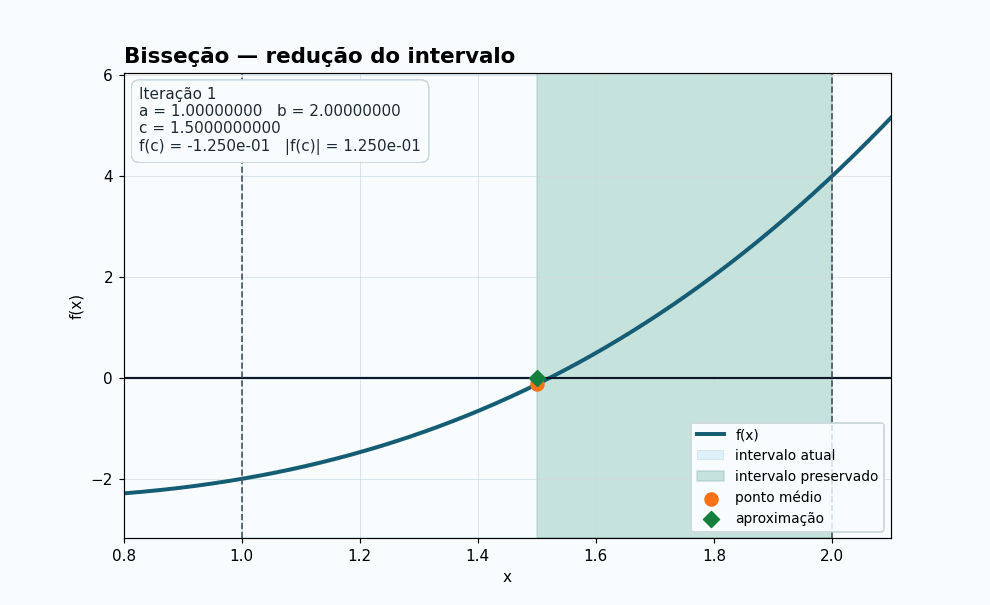

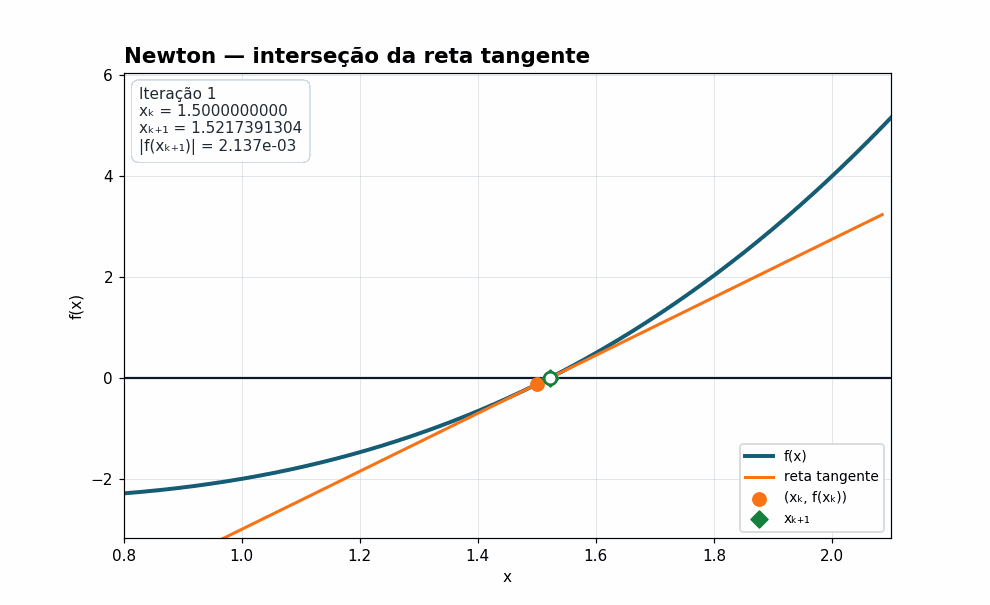

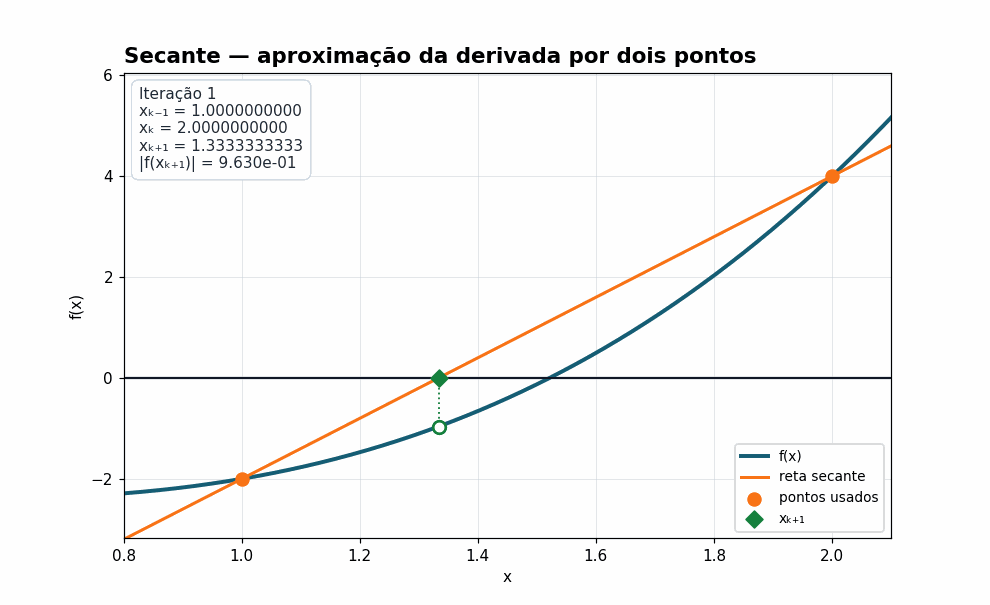

In [10]:
CAMINHOS_GIFS = {
    "Bisseção": animar_bissecao(
        f2, resultados_detalhados[("f2", "Bisseção")], (0.8, 2.1),
        GIF_DIR / "bissecao_f2.gif",
    ),
    "Newton": animar_newton(
        f2, df2, resultados_detalhados[("f2", "Newton")], (0.8, 2.1),
        GIF_DIR / "newton_f2.gif",
    ),
    "Secante": animar_secante(
        f2, resultados_detalhados[("f2", "Secante")], (0.8, 2.1),
        GIF_DIR / "secante_f2.gif",
    ),
}

for metodo, caminho in CAMINHOS_GIFS.items():
    print(f"{metodo}: {caminho}")
    display(IPythonImage(filename=str(caminho)))

## 10. Discussão dos resultados

Nos resultados executados, a **Bisseção** precisou de **20 e 22 iterações**, faixa estreita que evidencia sua regularidade. Ela foi a mais lenta, mas sua raiz permaneceu delimitada pelo intervalo com mudança de sinal.

**Newton** terminou em **3 e 4 iterações**, sendo o método mais rápido nos 12 casos. Essa eficiência veio ao custo de derivadas analíticas e de maior sensibilidade ao ponto inicial.

A **Secante** convergiu em **5 a 7 iterações**: mais lenta que Newton, porém mais rápida que a Bisseção e sem exigir derivada. Seus resultados finais ficaram praticamente iguais aos de Newton, com resíduos entre aproximadamente $10^{-16}$ e $10^{-11}$.

Assim, não existe método universalmente superior: a Bisseção privilegia robustez, Newton privilegia velocidade e a Secante oferece um compromisso útil quando a derivada não está disponível.

## 11. Estudo de f4

### Resultados com os valores solicitados

Com o intervalo `[-2,-1]`, `x0=-2` e o par `(-2,-1)`, os três métodos convergiram para aproximadamente `-1.7692923542`. Newton precisou de 4 iterações, a Secante de 7 e a Bisseção de 21.

### Experimentos adicionais

Com `x0=0`, Newton produz `0 → 1 → 0 → 1 → …`: $f_4(0)=2$, $f'_4(0)=-2$, então $x_1=1$; depois $f_4(1)=1$ e $f'_4(1)=1$, retornando a $x_2=0$. O método termina por `max_iter=100`, sem convergência. Esse caso demonstra por que resultados inesperados não devem ser ocultados nem corrigidos pela troca silenciosa do ponto inicial.

In [11]:
resultado_f4_ciclo = newton(f4, df4, x0=0.0, tol=TOL, max_iter=MAX_ITER)
resumo_f4_ciclo = {
    "convergiu": resultado_f4_ciclo["convergiu"],
    "iteracoes": resultado_f4_ciclo["iteracoes"],
    "primeiras_aproximacoes": resultado_f4_ciclo["historico"][:8],
    "mensagem": resultado_f4_ciclo["mensagem"],
}
resumo_f4_ciclo

{'convergiu': False, 'iteracoes': 100, 'primeiras_aproximacoes': [0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0], 'mensagem': 'Número máximo de 100 iterações atingido sem convergência.'}

## 12. Conclusões

Os três métodos resolveram todos os casos principais dentro da tolerância. A Bisseção apresentou o comportamento mais previsível; Newton foi o mais eficiente quando o ponto inicial e a derivada foram adequados; e a Secante alcançou precisão semelhante sem derivada analítica. O ciclo de Newton em `f4` com `x0=0` confirma que condições iniciais fazem parte do problema numérico, não apenas da configuração do código.

# Resumo para o Dashboard

### Bloco 1 — Problema
Encontrar numericamente raízes de funções por Bisseção, Newton e Secante.

### Bloco 2 — Métodos
Inserir as três fórmulas e as palavras-chave **intervalo**, **tangente** e **dois pontos**.

### Bloco 3 — Resultados
Inserir a tabela de 12 casos criada acima.

### Bloco 4 — Visualização
Inserir `bissecao_f2.gif`, `newton_f2.gif` e `secante_f2.gif` lado a lado.

### Bloco 5 — Conclusões
Destacar: 12/12 convergências principais; Newton em 3–4 iterações; Secante em 5–7; Bisseção em 20–22; sensibilidade de Newton em `f4`.

In [12]:
def _geometria_dashboard():
    return {
        "objetivo_y": 0.66,
        "cartoes_center_y": 0.18,
        "cartoes_top": 0.40,
    }


def _frame_representativo(caminho):
    with PILImage.open(caminho) as imagem:
        imagem.seek(max(0, getattr(imagem, "n_frames", 1) // 2))
        return np.asarray(imagem.convert("RGB"))


def gerar_dashboard_preview(df, caminho, colab_url=COLAB_URL):
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)

    fig = plt.figure(figsize=(12, 22), dpi=100, facecolor="#F8FAFC")
    grade = fig.add_gridspec(
        6, 1, height_ratios=[1.0, 1.0, 3.3, 5.0, 1.7, 0.45], hspace=0.18
    )

    cabecalho = fig.add_subplot(grade[0])
    cabecalho.axis("off")
    cabecalho.text(
        0.02, 0.78, "Cálculo Numérico — Atividade Prática III",
        fontsize=25, fontweight="bold", color="#0F3D4C", va="top",
    )
    cabecalho.text(
        0.02, 0.43, "Raízes por Bisseção, Newton e Secante",
        fontsize=15, color="#334155", va="top",
    )
    texto_link = colab_url
    cabecalho.text(
        0.02, 0.12, texto_link, fontsize=11, color="#0E7490", va="top",
        bbox={"boxstyle": "round,pad=0.45", "facecolor": "#ECFEFF", "edgecolor": "#67E8F9"},
    )

    metodos = fig.add_subplot(grade[1])
    metodos.axis("off")
    geometria = _geometria_dashboard()
    metodos.text(0.02, 0.96, "Problema e métodos", fontsize=17, fontweight="bold", color="#0F3D4C", va="top")
    metodos.text(0.02, geometria["objetivo_y"], "Encontrar aproximações para f(x)=0.", fontsize=12, color="#334155", va="top")
    cartoes = [
        (0.02, "BISSEÇÃO", "c = (a+b)/2\nintervalo com mudança de sinal"),
        (0.35, "NEWTON", "xₖ₊₁ = xₖ − f(xₖ)/f′(xₖ)\nreta tangente"),
        (
            0.68,
            "SECANTE",
            "xₖ₊₁ = xₖ − f(xₖ)·\n(xₖ−xₖ₋₁)/(f(xₖ)−f(xₖ₋₁))",
        ),
    ]
    for x, titulo, formula in cartoes:
        metodos.text(
            x, geometria["cartoes_center_y"], f"{titulo}\n{formula}", fontsize=11, color="#1F2937", va="center",
            bbox={"boxstyle": "round,pad=0.62", "facecolor": "white", "edgecolor": "#CBD5E1"},
        )

    grade_gifs = grade[2].subgridspec(1, 3, wspace=0.08)
    gifs = [
        ("Bisseção — redução do intervalo", GIF_DIR / "bissecao_f2.gif"),
        ("Newton — reta tangente", GIF_DIR / "newton_f2.gif"),
        ("Secante — reta secante", GIF_DIR / "secante_f2.gif"),
    ]
    for indice, (titulo, gif) in enumerate(gifs):
        ax = fig.add_subplot(grade_gifs[0, indice])
        ax.imshow(_frame_representativo(gif))
        ax.set_title(titulo, fontsize=12, fontweight="bold", color="#0F3D4C", pad=10)
        ax.axis("off")

    tabela_ax = fig.add_subplot(grade[3])
    tabela_ax.axis("off")
    tabela_ax.set_title("Resultados dos 12 testes", loc="left", fontsize=18, fontweight="bold", color="#0F3D4C", pad=12)
    tabela_dashboard = pd.DataFrame(
        {
            "Função": df["Função"].str.extract(r"^(f\d)", expand=False),
            "Método": df["Método"],
            "Iniciais": df["Valores iniciais"],
            "Raiz aproximada": df["Raiz aproximada"].map(lambda x: f"{x:.10f}"),
            "|f(x)| final": df["|f(x)| final"].map(lambda x: f"{x:.2e}"),
            "Iter.": df["Iterações"].astype(str),
            "Resultado": df["Resultado"],
        }
    )
    tabela = tabela_ax.table(
        cellText=tabela_dashboard.values,
        colLabels=tabela_dashboard.columns,
        cellLoc="center",
        colLoc="center",
        loc="center",
        colWidths=[0.07, 0.12, 0.14, 0.20, 0.15, 0.08, 0.13],
    )
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(9.5)
    tabela.scale(1.0, 2.05)
    for (linha, _), celula in tabela.get_celld().items():
        celula.set_edgecolor("#CBD5E1")
        if linha == 0:
            celula.set_facecolor("#155E75")
            celula.set_text_props(color="white", fontweight="bold")
        elif linha % 2 == 0:
            celula.set_facecolor("#F1F5F9")
        else:
            celula.set_facecolor("white")

    conclusoes = fig.add_subplot(grade[4])
    conclusoes.axis("off")
    conclusoes.text(0.02, 0.96, "Leituras principais", fontsize=18, fontweight="bold", color="#0F3D4C", va="top")
    bullets = (
        "• Os 12 casos principais convergiram e satisfizeram |f(x)| < 10⁻⁶.\n"
        "• Newton foi o mais rápido: 3–4 iterações; exige derivada e bom x₀.\n"
        "• A Secante precisou de 5–7 iterações e dispensou derivadas analíticas.\n"
        "• A Bisseção usou 20–22 iterações, mas manteve a raiz sempre delimitada.\n"
        "• Para f4, Newton com x₀=0 entra no ciclo 0 → 1 → 0; com x₀=−2 converge."
    )
    conclusoes.text(
        0.02, 0.72, bullets, fontsize=12.5, color="#334155", va="top", linespacing=1.65,
        bbox={"boxstyle": "round,pad=0.75", "facecolor": "white", "edgecolor": "#CBD5E1"},
    )

    rodape = fig.add_subplot(grade[5])
    rodape.axis("off")
    rodape.text(
        0.5, 0.5, "Tolerância: 10⁻⁶  ·  Máximo: 100 iterações  ·  Critério: passo E resíduo",
        ha="center", va="center", fontsize=11, color="#475569",
    )

    fig.savefig(caminho, dpi=100, facecolor=fig.get_facecolor())
    plt.close(fig)
    return caminho


DASHBOARD_PREVIEW = gerar_dashboard_preview(
    df_resultados, PROJECT_DIR / "dashboard_preview.png"
)
DASHBOARD_PREVIEW

PosixPath('dashboard_preview.png')

## Checklist final

- [x] Implementações manuais e genéricas dos três métodos
- [x] 12 testes principais executados
- [x] Resíduos convergentes abaixo de `1e-6`
- [x] CSV com sete colunas e 12 linhas
- [x] Um GIF para cada método
- [x] Experimento adicional de `f4` separado
- [x] Materiais e prévia para o Mathcha
- [x] Link compartilhável do Google Colab incluído no relatório e no dashboard